In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving retail_store_inventory.csv to retail_store_inventory (1).csv
Dataset loaded successfully!
Dataset shape: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [ ]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']


In [ ]:
# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['date', 'store_id', 'product_id', 'category', 'region', 'inventory_level', 'units_sold', 'units_ordered', 'demand_forecast', 'price', 'discount', 'weather_condition', 'holiday/promotion', 'competitor_pricing', 'seasonality']


In [ ]:
# Convert date column
df["date"] = pd.to_datetime(
    df["date"],
    dayfirst=True,
    errors="coerce"
)

# Remove rows with invalid dates
df = df.dropna(subset=["date"])

# Sort records by date
df = df.sort_values("date").reset_index(drop=True)

print("Date conversion completed!")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Date conversion completed!
Start date: 2022-01-01 00:00:00
End date: 2024-01-01 00:00:00


In [ ]:
print("Missing values:")
display(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:


,0
date,0
store_id,0
product_id,0
category,0
region,0
inventory_level,0
units_sold,0
units_ordered,0
demand_forecast,0
price,0


Duplicate rows: 0


In [ ]:
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(
        df[col].mode()[0] if not df[col].mode().empty else "Unknown"
    )

print("Missing values handled!")

Missing values handled!


In [ ]:
required_columns = [
    "date",
    "store_id",
    "product_id",
    "inventory_level",
    "units_sold"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

print("All required columns are available!")

All required columns are available!


In [ ]:
print("Number of records:", len(df))
print("Number of stores:", df["store_id"].nunique())
print("Number of products:", df["product_id"].nunique())

print("\nStatistical summary:")
display(df.describe())

Number of records: 28900
Number of stores: 5
Number of products: 20

Statistical summary:


,date,inventory_level,units_sold,units_ordered,demand_forecast,price,discount,holiday/promotion,competitor_pricing
count,28900,28900.000000,28900.000000,28900.000000,28900.000000,28900.000000,28900.000000,28900.000000,28900.000000
mean,2022-12-22 19:11:00.207612672,274.013114,135.856574,110.041765,140.865162,55.145651,10.026471,0.497059,55.144635
min,2022-01-01 00:00:00,50.000000,0.000000,20.000000,-9.990000,10.010000,0.000000,0.000000,5.030000
25%,2022-07-01 00:00:00,163.000000,47.000000,65.000000,52.777500,32.357500,5.000000,0.000000,32.480000
50%,2023-01-01 00:00:00,273.000000,107.000000,110.000000,111.805000,55.075000,10.000000,0.000000,54.980000
75%,2023-07-01 00:00:00,385.000000,202.000000,155.000000,207.620000,78.132500,15.000000,1.000000,77.970000
max,2024-01-01 00:00:00,500.000000,496.000000,200.000000,512.360000,99.990000,20.000000,1.000000,104.940000
std,NaN,129.536500,109.287094,52.181581,109.536891,26.093873,7.086233,0.500000,26.272668


In [ ]:
print("Total units sold:", df["units_sold"].sum())

print(
    "Average daily units sold:",
    round(df["units_sold"].mean(), 2)
)

Total units sold: 3926255
Average daily units sold: 135.86


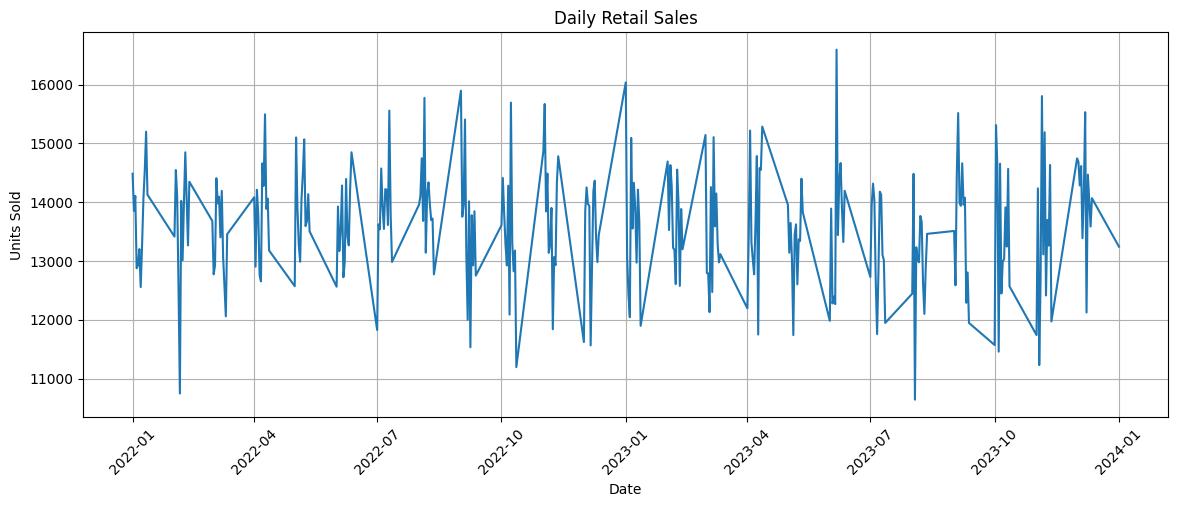

In [ ]:
daily_sales = (
    df.groupby("date")["units_sold"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_sales["date"],
    daily_sales["units_sold"]
)

plt.title("Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

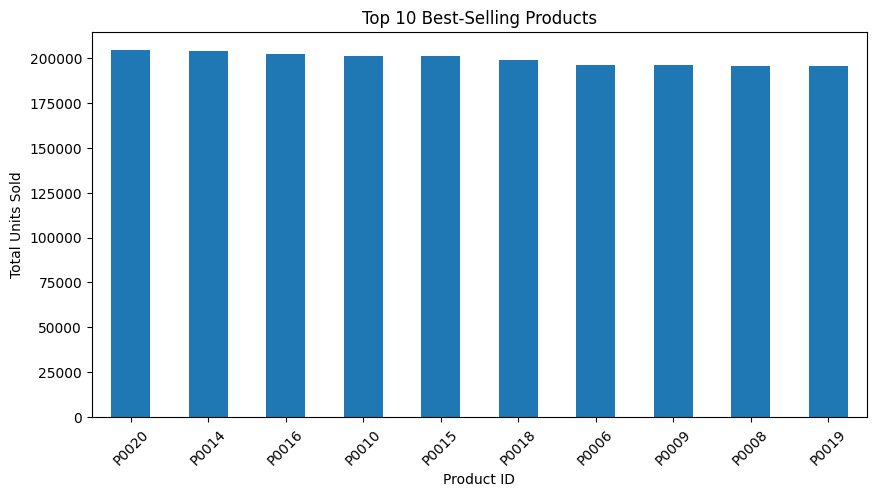

In [ ]:
top_products = (
    df.groupby("product_id")["units_sold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))

top_products.plot(kind="bar")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.show()

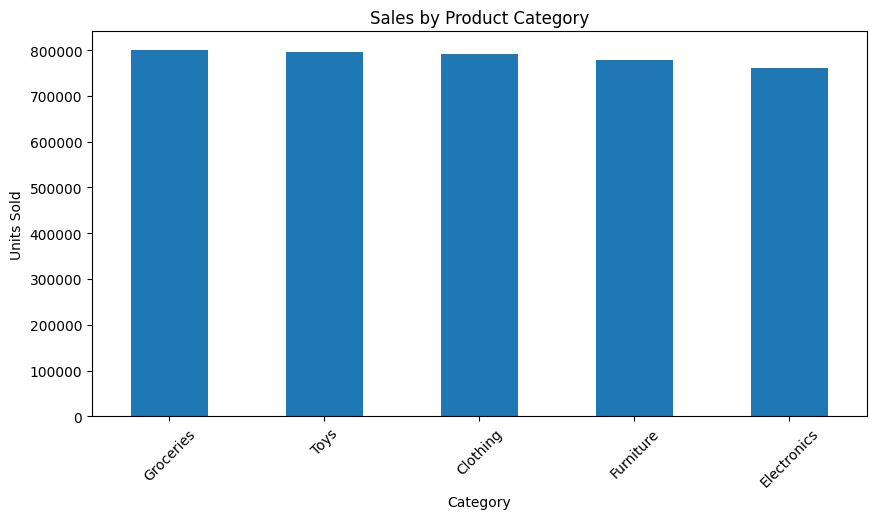

In [ ]:
if "category" in df.columns:

    category_sales = (
        df.groupby("category")["units_sold"]
        .sum()
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))
    category_sales.plot(kind="bar")

    plt.title("Sales by Product Category")
    plt.xlabel("Category")
    plt.ylabel("Units Sold")
    plt.xticks(rotation=45)
    plt.show()

else:
    print("Category column is not available.")


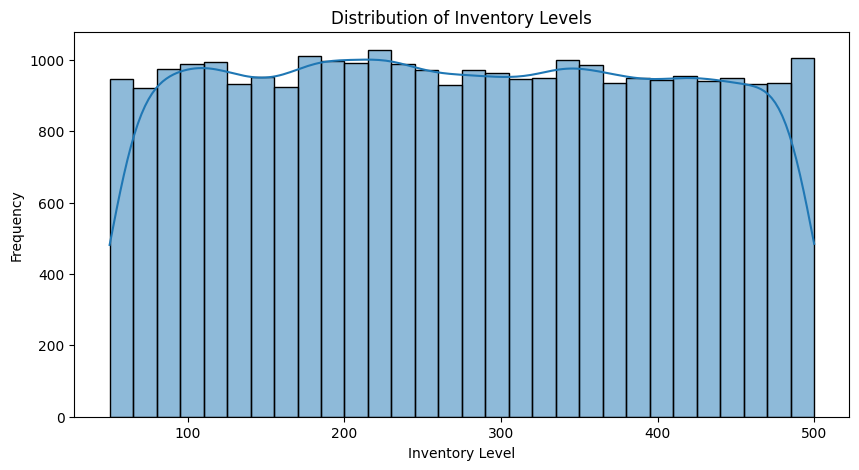

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["inventory_level"],
    bins=30,
    kde=True
)

plt.title("Distribution of Inventory Levels")
plt.xlabel("Inventory Level")
plt.ylabel("Frequency")
plt.show()

In [ ]:
TARGET = "units_sold"

# Identify product and store combinations
GROUP_COLS = ["store_id", "product_id"]

# Keep one record per date/store/product
df = (
    df.sort_values("date")
    .drop_duplicates(
        subset=["date", "store_id", "product_id"],
        keep="last"
    )
    .copy()
)

# Make sales non-negative
df[TARGET] = df[TARGET].clip(lower=0)

print("Target variable:", TARGET)

Target variable: units_sold


In [ ]:
# Calendar features
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

# Sort data before creating lag features
df = df.sort_values(
    GROUP_COLS + ["date"]
).reset_index(drop=True)

# Previous sales
df["lag_1"] = (
    df.groupby(GROUP_COLS)[TARGET].shift(1)
)

df["lag_7"] = (
    df.groupby(GROUP_COLS)[TARGET].shift(7)
)

df["lag_14"] = (
    df.groupby(GROUP_COLS)[TARGET].shift(14)
)

df["lag_28"] = (
    df.groupby(GROUP_COLS)[TARGET].shift(28)
)

# Rolling averages using only previous days
df["rolling_mean_7"] = (
    df.groupby(GROUP_COLS)[TARGET]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

df["rolling_mean_28"] = (
    df.groupby(GROUP_COLS)[TARGET]
    .transform(
        lambda x: x.shift(1).rolling(28).mean()
    )
)

# Rolling demand variability
df["rolling_std_28"] = (
    df.groupby(GROUP_COLS)[TARGET]
    .transform(
        lambda x: x.shift(1).rolling(28).std()
    )
)

print("Feature engineering completed!")
display(df.head(10))

Feature engineering completed!


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,...,day_of_week,month,day,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_28
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,...,5,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-02,S001,P0001,Groceries,East,419,279,84,297.26,34.49,...,6,1,2,127.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-03,S001,P0001,Toys,North,263,28,113,33.68,15.95,...,0,1,3,279.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-04,S001,P0001,Furniture,West,215,101,65,102.74,44.62,...,1,1,4,28.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-05,S001,P0001,Electronics,East,125,0,117,-8.04,36.91,...,2,1,5,101.0,NaN,NaN,NaN,NaN,NaN,NaN
5,2022-01-06,S001,P0001,Toys,North,461,198,119,192.58,11.52,...,3,1,6,0.0,NaN,NaN,NaN,NaN,NaN,NaN
6,2022-01-07,S001,P0001,Clothing,South,372,35,152,37.91,43.74,...,4,1,7,198.0,NaN,NaN,NaN,NaN,NaN,NaN
7,2022-01-08,S001,P0001,Furniture,West,73,67,149,75.93,28.22,...,5,1,8,35.0,127.0,NaN,NaN,109.714286,NaN,NaN
8,2022-01-09,S001,P0001,Electronics,South,61,17,49,32.92,50.89,...,6,1,9,67.0,279.0,NaN,NaN,101.142857,NaN,NaN
9,2022-01-10,S001,P0001,Clothing,West,212,201,20,209.06,58.74,...,0,1,10,17.0,28.0,NaN,NaN,63.714286,NaN,NaN


In [ ]:
feature_columns = [
    "store_id",
    "product_id",
    "day_of_week",
    "month",
    "day",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28"
]

# Add category when available
if "category" in df.columns:
    feature_columns.append("category")

df_model = df.dropna(
    subset=feature_columns + [TARGET]
).copy()

print("Rows available for modeling:", len(df_model))

Rows available for modeling: 26100


In [ ]:
unique_dates = sorted(df_model["date"].unique())

if len(unique_dates) < 2:
    raise ValueError("Not enough dates for time-based evaluation.")

# Use the last 30 days for testing
test_days = min(30, max(1, len(unique_dates) // 5))

split_date = unique_dates[-test_days]

train_df = df_model[
    df_model["date"] < split_date
].copy()

test_df = df_model[
    df_model["date"] >= split_date
].copy()

X_train = train_df[feature_columns]
y_train = train_df[TARGET]

X_test = test_df[feature_columns]
y_test = test_df[TARGET]

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Test begins:", split_date)

Training records: 23100
Testing records: 3000
Test begins: 2023-10-08 00:00:00


In [ ]:
# Identify categorical and numerical columns
categorical_features = [
    col for col in ["store_id", "product_id", "category"]
    if col in feature_columns
]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Convert categorical data into numeric form
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Build the model
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
# Predict test data
predictions = model.predict(X_test)

# Sales cannot be negative
predictions = np.maximum(predictions, 0)

# Evaluation metrics
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
MAE: 91.12
RMSE: 110.74
R2 Score: -0.0061


In [ ]:
comparison = test_df[
    ["date", "store_id", "product_id", TARGET]
].copy()

comparison["predicted_sales"] = predictions

display(comparison.head(20))

,date,store_id,product_id,units_sold,predicted_sales
259,2023-10-08,S001,P0001,176,128.447903
260,2023-10-09,S001,P0001,96,126.640651
261,2023-10-10,S001,P0001,32,130.273827
262,2023-10-11,S001,P0001,234,125.902006
263,2023-10-12,S001,P0001,283,137.033141
264,2023-11-01,S001,P0001,259,133.752316
265,2023-11-02,S001,P0001,354,131.524065
266,2023-11-03,S001,P0001,85,129.114684
267,2023-11-04,S001,P0001,61,138.399347
268,2023-11-05,S001,P0001,31,128.378012


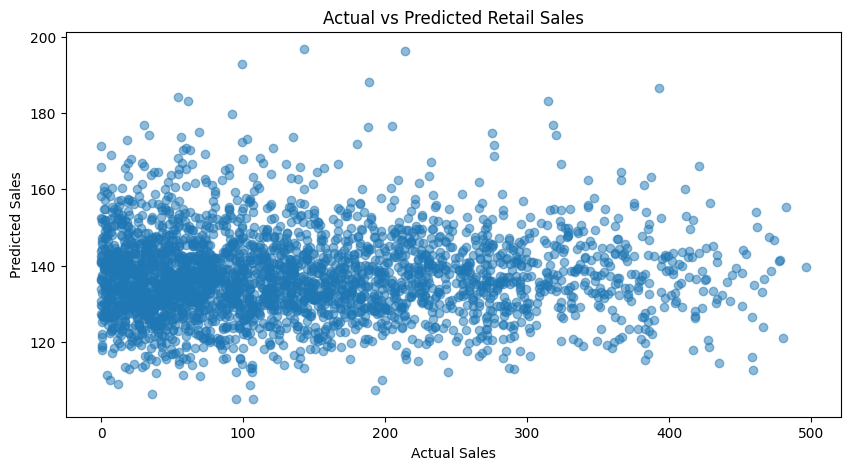

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Retail Sales")

plt.show()

In [ ]:
# Get the latest record for each store-product combination
latest_data = (
    df.sort_values("date")
    .groupby(GROUP_COLS)
    .tail(1)
    .copy()
)

# Calculate historical demand statistics
demand_stats = (
    df.groupby(GROUP_COLS)[TARGET]
    .agg(
        average_daily_demand="mean",
        demand_std="std"
    )
    .reset_index()
)

latest_data = latest_data.merge(
    demand_stats,
    on=GROUP_COLS,
    how="left"
)

latest_data["demand_std"] = (
    latest_data["demand_std"].fillna(0)
)

print("Latest inventory records:")
display(latest_data.head())

Latest inventory records:


,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,demand_forecast,price,...,day,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_28,average_daily_demand,demand_std
0,2024-01-01,S003,P0010,Furniture,East,413,398,186,409.17,80.87,...,1,378.0,71.0,198.0,10.0,213.142857,177.714286,122.275299,139.723183,110.395342
1,2024-01-01,S005,P0018,Clothing,West,278,36,151,39.65,11.11,...,1,49.0,417.0,151.0,61.0,130.285714,124.392857,117.779562,140.269896,116.119445
2,2024-01-01,S002,P0006,Toys,East,160,159,78,151.48,19.06,...,1,221.0,324.0,93.0,98.0,177.571429,101.071429,90.333919,128.930796,103.160922
3,2024-01-01,S002,P0007,Toys,West,53,2,40,-6.08,63.66,...,1,55.0,35.0,458.0,211.0,70.285714,126.321429,122.034620,134.235294,111.102899
4,2024-01-01,S002,P0008,Furniture,North,218,43,144,51.52,90.38,...,1,13.0,108.0,158.0,65.0,75.857143,129.178571,106.158879,125.498270,101.658371


In [ ]:
# Tomorrow's date
forecast_date = df["date"].max() + pd.Timedelta(days=1)

forecast_input = latest_data.copy()

forecast_input["day_of_week"] = forecast_date.dayofweek
forecast_input["month"] = forecast_date.month
forecast_input["day"] = forecast_date.day

# Use recent sales history for each product
forecast_input["lag_1"] = (
    forecast_input["units_sold"]
)

forecast_input["lag_7"] = (
    forecast_input["lag_7"]
)

forecast_input["lag_14"] = (
    forecast_input["lag_14"]
)

forecast_input["lag_28"] = (
    forecast_input["lag_28"]
)

# Keep the latest rolling averages
forecast_input["rolling_mean_7"] = (
    forecast_input["rolling_mean_7"]
)

forecast_input["rolling_mean_28"] = (
    forecast_input["rolling_mean_28"]
)

forecast_input["rolling_std_28"] = (
    forecast_input["rolling_std_28"]
)

# Make sure all model features are present
X_future = forecast_input[feature_columns]

# Predict next-day demand
forecast_input["predicted_demand"] = np.maximum(
    model.predict(X_future),
    0
)

forecast_input["predicted_7_day_demand"] = (
    forecast_input["predicted_demand"] * 7
).round(0)

print("Demand forecasting completed!")

display(
    forecast_input[
        GROUP_COLS + [
            "predicted_demand",
            "predicted_7_day_demand"
        ]
    ].head(20)
)

Demand forecasting completed!


,store_id,product_id,predicted_demand,predicted_7_day_demand
0,S003,P0010,131.777827,922.0
1,S005,P0018,153.970343,1078.0
2,S002,P0006,128.456528,899.0
3,S002,P0007,135.849335,951.0
4,S002,P0008,145.549475,1019.0
5,S002,P0009,141.696819,992.0
6,S002,P0010,147.984399,1036.0
7,S002,P0011,146.233769,1024.0
8,S002,P0012,133.599453,935.0
9,S002,P0013,152.372683,1067.0


In [ ]:
# Inventory planning assumptions
LEAD_TIME = 7
REVIEW_PERIOD = 7
SERVICE_FACTOR = 1.65

# Calculate safety stock
forecast_input["safety_stock"] = (
    SERVICE_FACTOR
    * forecast_input["demand_std"]
    * np.sqrt(LEAD_TIME)
)

# Calculate reorder point
forecast_input["reorder_point"] = (
    forecast_input["average_daily_demand"]
    * LEAD_TIME
    + forecast_input["safety_stock"]
)

# Calculate target inventory
forecast_input["target_inventory"] = (
    forecast_input["average_daily_demand"]
    * (LEAD_TIME + REVIEW_PERIOD)
    + forecast_input["safety_stock"]
)

# Current inventory
forecast_input["current_stock"] = (
    forecast_input["inventory_level"]
)

# Recommended order quantity
forecast_input["recommended_order"] = np.maximum(
    0,
    np.ceil(
        forecast_input["target_inventory"]
        - forecast_input["current_stock"]
    )
)

# Inventory status
forecast_input["inventory_status"] = np.where(
    forecast_input["current_stock"]
    <= forecast_input["reorder_point"],
    "Reorder Needed",
    "Stock Sufficient"
)

# Round values for display
round_columns = [
    "predicted_demand",
    "average_daily_demand",
    "safety_stock",
    "reorder_point",
    "target_inventory"
]

forecast_input[round_columns] = (
    forecast_input[round_columns].round(2)
)

print("Inventory optimization completed!")

Inventory optimization completed!


In [ ]:
inventory_report = forecast_input[
    GROUP_COLS + [
        "current_stock",
        "predicted_demand",
        "predicted_7_day_demand",
        "reorder_point",
        "recommended_order",
        "inventory_status"
    ]
].copy()

display(
    inventory_report.sort_values(
        "recommended_order",
        ascending=False
    ).head(30)
)

,store_id,product_id,current_stock,predicted_demand,predicted_7_day_demand,reorder_point,recommended_order,inventory_status
77,S003,P0012,108,152.37,1067.0,1538.26,2458.0,Reorder Needed
75,S004,P0015,56,149.78,1048.0,1487.37,2427.0,Reorder Needed
29,S001,P0003,69,134.62,942.0,1473.84,2403.0,Reorder Needed
81,S003,P0016,166,128.41,899.0,1524.69,2400.0,Reorder Needed
79,S003,P0014,230,132.53,928.0,1573.69,2394.0,Reorder Needed
58,S005,P0003,98,129.43,906.0,1497.51,2389.0,Reorder Needed
54,S004,P0019,65,128.51,900.0,1459.82,2362.0,Reorder Needed
24,S003,P0007,108,147.21,1030.0,1475.89,2360.0,Reorder Needed
62,S005,P0007,59,156.94,1099.0,1455.37,2352.0,Reorder Needed
5,S002,P0009,62,141.70,992.0,1445.53,2351.0,Reorder Needed


In [ ]:
low_stock = inventory_report[
    inventory_report["inventory_status"]
    == "Reorder Needed"
]

print("Products requiring restocking:", len(low_stock))

display(low_stock)

Products requiring restocking: 100


,store_id,product_id,current_stock,predicted_demand,predicted_7_day_demand,reorder_point,recommended_order,inventory_status
0,S003,P0010,413,131.78,922.0,1459.97,2026.0,Reorder Needed
1,S005,P0018,278,153.97,1078.0,1488.81,2193.0,Reorder Needed
2,S002,P0006,160,128.46,899.0,1352.86,2096.0,Reorder Needed
3,S002,P0007,53,135.85,951.0,1424.70,2312.0,Reorder Needed
4,S002,P0008,218,145.55,1019.0,1322.29,1983.0,Reorder Needed
...,...,...,...,...,...,...,...,...
95,S004,P0010,382,143.35,1003.0,1493.61,2109.0,Reorder Needed
96,S004,P0011,155,155.52,1089.0,1425.85,2225.0,Reorder Needed
97,S004,P0012,85,132.92,930.0,1361.27,2189.0,Reorder Needed
98,S004,P0014,386,141.41,990.0,1579.90,2265.0,Reorder Needed


In [ ]:
out_of_stock = inventory_report[
    inventory_report["current_stock"] <= 0
]

print("Out-of-stock products:", len(out_of_stock))

display(out_of_stock)

Out-of-stock products: 0


,store_id,product_id,current_stock,predicted_demand,predicted_7_day_demand,reorder_point,recommended_order,inventory_status


In [ ]:
sufficient_stock = inventory_report[
    inventory_report["inventory_status"]
    == "Stock Sufficient"
]

print("Products with sufficient stock:", len(sufficient_stock))

Products with sufficient stock: 0


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Dashboard summary
total_products = len(inventory_report)

products_to_reorder = (
    inventory_report["inventory_status"]
    == "Reorder Needed"
).sum()

total_order_quantity = (
    inventory_report["recommended_order"].sum()
)

out_of_stock_count = (
    inventory_report["current_stock"] <= 0
).sum()

print("===== RETAIL INVENTORY DASHBOARD =====")
print("Total Store-Product Records:", total_products)
print("Products Requiring Reorder:", products_to_reorder)
print("Out-of-Stock Products:", out_of_stock_count)
print("Total Recommended Units to Order:", total_order_quantity)

===== RETAIL INVENTORY DASHBOARD =====
Total Store-Product Records: 100
Products Requiring Reorder: 100
Out-of-Stock Products: 0
Total Recommended Units to Order: 211427.0


In [ ]:
store_options = sorted(
    inventory_report["store_id"].astype(str).unique()
)

store_dropdown = widgets.Dropdown(
    options=["All Stores"] + store_options,
    description="Store:"
)

search_button = widgets.Button(
    description="Show Inventory",
    button_style="primary"
)

output = widgets.Output()

def show_inventory(button):
    with output:
        clear_output()

        result = inventory_report.copy()

        if store_dropdown.value != "All Stores":
            result = result[
                result["store_id"].astype(str)
                == store_dropdown.value
            ]

        display(result)

search_button.on_click(show_inventory)

display(
    widgets.VBox([
        store_dropdown,
        search_button,
        output
    ])
)

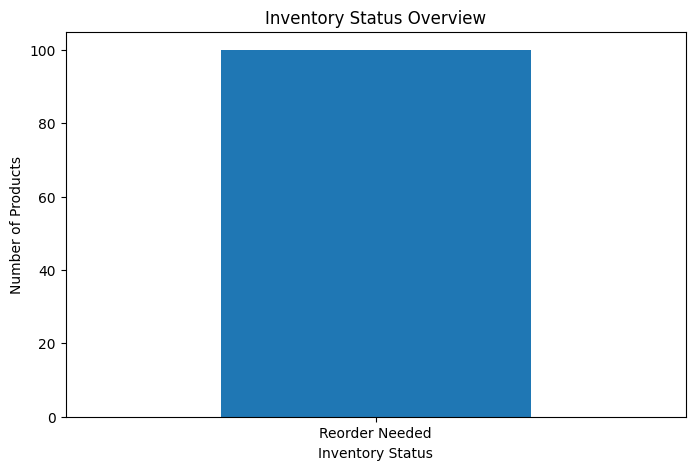

In [ ]:
status_counts = (
    inventory_report["inventory_status"]
    .value_counts()
)

plt.figure(figsize=(8, 5))

status_counts.plot(kind="bar")

plt.title("Inventory Status Overview")
plt.xlabel("Inventory Status")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)

plt.show()

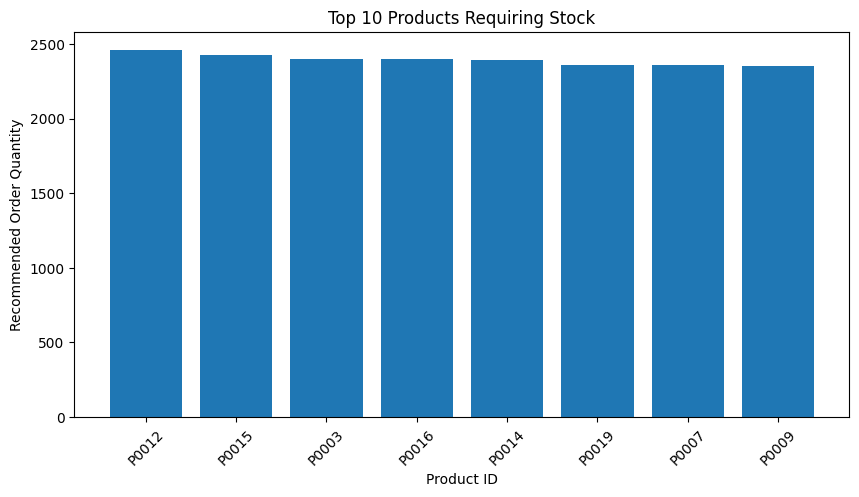

In [ ]:
top_orders = (
    inventory_report.sort_values(
        "recommended_order",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 5))

plt.bar(
    top_orders["product_id"].astype(str),
    top_orders["recommended_order"]
)

plt.title("Top 10 Products Requiring Stock")
plt.xlabel("Product ID")
plt.ylabel("Recommended Order Quantity")
plt.xticks(rotation=45)

plt.show()

In [ ]:
output_file = "optimized_retail_inventory_report.csv"

inventory_report.to_csv(
    output_file,
    index=False
)

print("Inventory report saved successfully!")

files.download(output_file)

Inventory report saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
evaluation_report = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

display(evaluation_report)

evaluation_report.to_csv(
    "model_evaluation.csv",
    index=False
)

,Metric,Value
0,MAE,91.121556
1,RMSE,110.741492
2,R2 Score,-0.006133
